# 01 · Fuzzy Scorer Comparison

**Goal:** pick the fuzzy matching scorers used to match typed client and matter names to Matter Master, the firm's list of clients and matters.

Fuzzy matching gives a 0 to 100 similarity score between what was typed and each known name, so "Bluefin Rbootlcs" still finds Bluefin Robotics. The top-scoring name is the match, and the gap to second place shows how confident it is.

**Questions**
1. Which scorer matches typed client names best, especially names that look like another client's?
2. Does matching the client first help when matching the matter?
3. How low do clients that aren't in Matter Master score, and can a cutoff catch them?

Choices are made on TRAIN and checked once on VAL. TEST stays untouched until the final model comparison.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from clean import normalize, is_ditto
from fuzzy import SCORERS, client_name_table, matter_name_table, score_table, match, compare_scorers, rank, exact_match_acc

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
TUNE, CHECK = "TRAIN", "VAL"

# Entries that resolve to one matter, so a typed client belongs to the true client
ONE_MATTER = ["CLEAN", "INCOMPLETE", "MESSY"]
CLIENT_FORMS = ["CANONICAL", "LISTED_ALIAS", "CASE", "MISSPELLED", "SHORT", "TRUNCATED", "LOOKALIKE"]
MATTER_FORMS = ["CANONICAL", "CODENAME", "CODENAME_TYPO", "DESCRIPTOR"]

## 2. Load data

A **client** is who the firm works for (Tidewater AI). A **matter** is one job for that client, like a deal or a lawsuit. The CMID holds both: in `4590.003`, `4590` is the client and `003` is the matter.

Everything is read as text so CMIDs keep their zeros.

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Time Entries", dtype=str)
matter_master = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str)
assert set(raw["KEY: Split"]) == {"TRAIN", "VAL", "TEST"}

client_names = client_name_table(matter_master)
matter_names = matter_name_table(matter_master)
client_cmids = matter_master.groupby("Client")["CMID"].agg(set).to_dict()

print(f"{len(raw):,} entries | {client_names['id'].nunique()} clients ({len(client_names)} names) | "
      f"{matter_names['id'].nunique()} matters ({len(matter_names)} names)")
client_names.head()

4,000 entries | 35 clients (76 names) | 103 matters (120 names)


,name,id,kind,name_norm
0,Firm,Firm,canonical,firm
1,Harborlight Bio,Harborlight Bio,canonical,harborlight bio
2,Harborlight,Harborlight Bio,alias,harborlight
3,Harborline Biosciences,Harborline Biosciences,canonical,harborline biosciences
4,Harborline,Harborline Biosciences,alias,harborline


## 3. How the scorers behave

| scorer | idea |
|---|---|
| `ratio` | edit distance on the whole string |
| `partial_ratio` | best match of the shorter string inside the longer one |
| `token_sort_ratio` | sorts the words first, so word order doesn't matter |
| `token_set_ratio` | compares shared words, so extra words don't matter |
| `WRatio` | a weighted blend of the above |
| `JaroWinkler` | rewards matching starts, popular for short names |

The pairs below are real typed values from the data.

In [4]:
examples = [("bluefin rbootlcs", "bluefin robotics", "typo"),
            ("cobalt ridge ca", "cobalt ridge capital", "cut off"),
            ("pelican", "pelican row holdings", "short form"),
            ("northgate bank partners", "northgate capital partners", "look-alike typo (right)"),
            ("northgate bank partners", "northgate bank", "look-alike typo (wrong client)"),
            ("prh", "pelican row holdings", "acronym")]

pd.DataFrame([{"typed": a, "name": b, "case": c, **{s: round(f(a, b) * m) for s, (f, m) in SCORERS.items()}}
              for a, b, c in examples])

,typed,name,case,ratio,partial_ratio,token_sort_ratio,token_set_ratio,WRatio,JaroWinkler
0,bluefin rbootlcs,bluefin robotics,typo,88,88,88,88,88,96
1,cobalt ridge ca,cobalt ridge capital,cut off,86,100,86,89,86,95
2,pelican,pelican row holdings,short form,52,100,52,100,90,87
3,northgate bank partners,northgate capital partners,look-alike typo (right),82,74,82,88,83,91
4,northgate bank partners,northgate bank,look-alike typo (wrong client),76,100,76,100,90,92
5,prh,pelican row holdings,acronym,26,50,17,17,45,59


- `partial_ratio` and `token_set_ratio` give "pelican" a perfect score against any name containing it, so they can't tell Pelican Row from Pelican Bay.
- "northgate bank partners" scores high against both Northgate clients with every scorer. Only the gap between the two decides it.
- No scorer links "prh" to Pelican Row Holdings. Acronyms that aren't listed as aliases need other clues.

## 4. Client names

Only entries that resolve to one matter, where the typed client is some version of the true client's name.

In [5]:
def client_rows(split):
    keep = ((raw["KEY: Split"] == split) & raw["Client"].notna() & ~raw["Client"].map(is_ditto)
            & raw["KEY: Entry Category"].isin(ONE_MATTER) & raw["KEY: Client Surface"].isin(CLIENT_FORMS))
    df = raw.loc[keep, ["Client", "KEY: True Client", "KEY: Client Surface"]]
    df.columns = ["typed", "true_id", "form"]
    return df.assign(typed_norm=df["typed"].map(normalize)).reset_index(drop=True)


clients_train, clients_val = client_rows(TUNE), client_rows(CHECK)
client_results, client_ranked = compare_scorers(clients_train, client_names)
print(f"{len(clients_train)} TRAIN rows | exact match only: {exact_match_acc(clients_train, client_names):.1%}")
client_results.sort_values("top1_acc", ascending=False).round(3)

1269 TRAIN rows | exact match only: 80.9%


,top1_acc,recall@3,median_gap,min_gap
scorer,,,,
ratio,0.990,1.0,26.829,0.575
token_sort_ratio,0.983,1.0,28.000,0.575
JaroWinkler,0.979,1.0,10.819,0.513
WRatio,0.978,1.0,18.489,0.000
token_set_ratio,0.960,1.0,22.222,0.000
partial_ratio,0.956,1.0,15.000,0.000


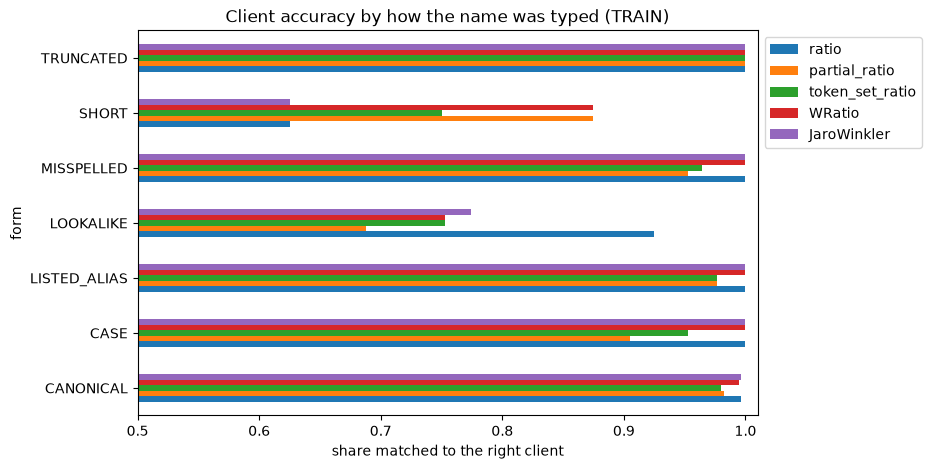

In [6]:
by_form = pd.DataFrame({s: r.groupby("form")["correct"].mean() for s, r in client_ranked.items()})
ax = by_form.drop(columns="token_sort_ratio").plot.barh(figsize=(8, 5), xlim=(0.5, 1.01), title="Client accuracy by how the name was typed (TRAIN)")
ax.set_xlabel("share matched to the right client")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- Exact matching alone gets about 81%. Every scorer gets above 95%, and `ratio` is best at 99%.
- **Look-alike typos separate the scorers:** `ratio` gets 92% on them, while `partial_ratio`, `token_set_ratio`, and `WRatio` drop to 69 to 75%.
- Short forms ("Pelican") go the other way, but there are only a handful, and many fit two real clients anyway.

In [7]:
misses = client_ranked["ratio"].query("not correct")
misses[["typed", "form", "true_id", "pred_id", "gap"]].round(1)

,typed,form,true_id,pred_id,gap
127,Halvorsen Industries,LOOKALIKE,Halvorsen Industrial,Halverson Industries,0.0
140,Cobalt Ridge,CANONICAL,Cobalt Ridge Partners,Cobalt Ridge Capital,2.3
158,Meridian Therapeutics Systems,LOOKALIKE,Meridian Thermal Systems,Meridian Therapeutics,1.0
296,Pelican,SHORT,Pelican Row Holdings,Pelican Bay Holdings,0.0
524,Northgate,CANONICAL,Northgate Capital Partners,Northgate Bank,9.0
587,Coba1t,SHORT,Cobalt Ridge Capital,Cobalt Rock Capital,20.4
786,Halvorsen Industries,LOOKALIKE,Halvorsen Industrial,Halverson Industries,0.0
944,Harborlight Light,LOOKALIKE,Harborlight Bio,Harbor Light Partners,1.5
954,Harbor,SHORT,Harbor Light Partners,Harborline Biosciences,4.4
1011,Cobalt Ridg,LOOKALIKE,Cobalt Ridge Capital,Cobalt Rock Capital,1.8


- Most misses are short or cut-off names that fit two real clients ("Pelican", "Northgate", "Cobalt Ridge"), or typos between two look-alike clients. The narrative or timekeeper history has to settle these.

## 5. Matter names

Rows where a matter name or codename was typed. Two ways to match:
- **all matters:** compare against every matter in Matter Master
- **within the client:** match the typed client first, then only that client's matters

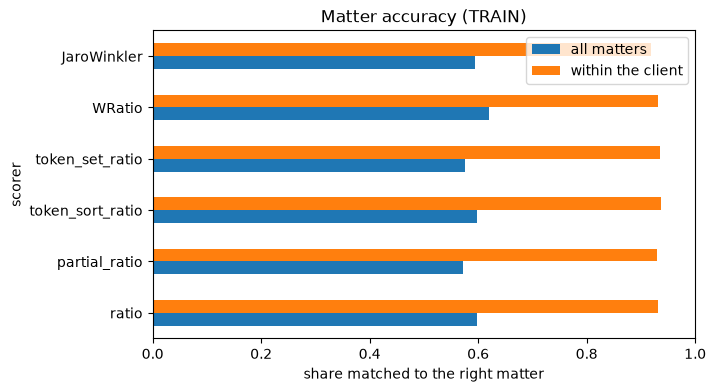

,top1_acc,recall@3,median_gap,min_gap
scorer,,,,
ratio,0.932,0.947,54.839001,0.0
partial_ratio,0.930,0.948,44.827999,0.0
token_sort_ratio,0.937,0.955,57.143002,0.0
token_set_ratio,0.935,0.955,53.487999,0.0
WRatio,0.932,0.948,53.784000,0.0
JaroWinkler,0.919,0.948,37.328999,0.0


In [8]:
def matter_rows(split):
    keep = ((raw["KEY: Split"] == split) & raw["Matter"].notna() & raw["KEY: Entry Category"].isin(ONE_MATTER)
            & raw["KEY: Matter Surface"].isin(MATTER_FORMS))
    df = raw.loc[keep, ["Matter", "Client", "KEY: True CMID", "KEY: Matter Surface"]]
    df.columns = ["typed", "typed_client", "true_id", "form"]
    return df.assign(typed_norm=df["typed"].map(normalize)).reset_index(drop=True)


def client_scope(df):
    top = [match(c, client_names, k=1) for c in df["typed_client"]]
    return [client_cmids[t[0][0]] if t else set() for t in top]


matters_train, matters_val = matter_rows(TUNE), matter_rows(CHECK)
all_matters, _ = compare_scorers(matters_train, matter_names)
within_client, matter_ranked = compare_scorers(matters_train, matter_names, allowed=client_scope(matters_train))

ax = pd.DataFrame({"all matters": all_matters["top1_acc"], "within the client": within_client["top1_acc"]}).plot.barh(
    figsize=(7, 4), xlim=(0, 1), title="Matter accuracy (TRAIN)")
ax.set_xlabel("share matched to the right matter")
plt.show()
within_client.round(3)

- **All matters:** about 60%. "General Corporate", the catch-all matter for a client's routine legal work, belongs to 18 clients, so the name alone can't pick one.
- **Within the client:** 92 to 94% for every scorer. Finding the client first is what makes matter names work.
- The scorers are within 2 points of each other here, so the order of steps matters more than the scorer.

In [9]:
matter_ranked["token_sort_ratio"].query("not correct")[["typed", "typed_client", "form", "true_id", "pred_id"]].head(8)

,typed,typed_client,form,true_id,pred_id
21,General Fund Matters,NaN,CODENAME,5524.002,2215.001
35,annual meeting,MT,DESCRIPTOR,6103.004,8820.002
37,sec reporting,Meridian Therapeutics,DESCRIPTOR,6103.004,6103.001
48,sec,Meridian Therapeutics,DESCRIPTOR,6103.004,6103.001
54,Fund II Formation,NaN,CODENAME,9140.001,2215.002
74,Vireo,LSG,DESCRIPTOR,9035.002,9028.004
89,gen,Cobalt Ridge Capital,DESCRIPTOR,5520.004,5520.002
90,gen corp,HB,DESCRIPTOR,2201.001,8340.002


- The remaining misses are short descriptors ("sec", "gen", "annual meeting") and matters typed with no client or an acronym client.

## 6. Clients that aren't in Matter Master

Some entries are for a new client the firm hasn't opened yet. The right output is `NO_MATCH`, so the question is how far these names score from real clients. Each typed name keeps its best score against any known client.

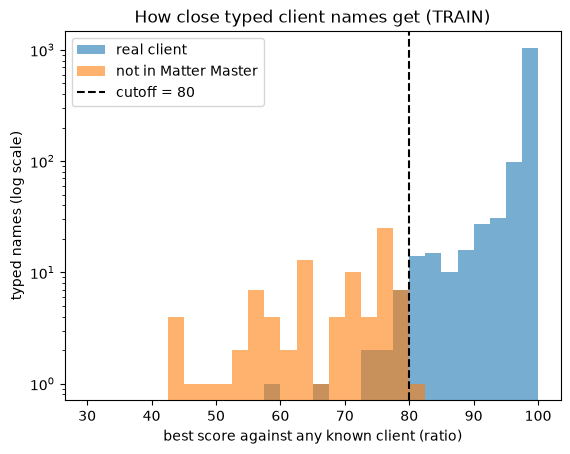

In [10]:
new_clients = raw[(raw["KEY: Split"] == TUNE) & (raw["KEY: Client Surface"] == "NOT_IN_MATTER_MASTER") & raw["Client"].notna()]
real_best = score_table(clients_train["typed_norm"], client_names, "ratio").max(axis=1)
new_best = score_table(new_clients["Client"].map(normalize), client_names, "ratio").max(axis=1)

bins = np.arange(30, 102.5, 2.5)
plt.hist(real_best, bins=bins, alpha=0.6, label="real client")
plt.hist(new_best, bins=bins, alpha=0.6, label="not in Matter Master")
plt.axvline(80, color="black", linestyle="--", label="cutoff = 80")
plt.yscale("log")
plt.xlabel("best score against any known client (ratio)")
plt.ylabel("typed names (log scale)")
plt.title("How close typed client names get (TRAIN)")
plt.legend()
plt.show()

In [11]:
cutoffs = pd.DataFrame({"real clients kept": [(real_best >= c).mean() for c in range(50, 96, 5)],
                        "new clients caught": [(new_best < c).mean() for c in range(50, 96, 5)]},
                       index=range(50, 96, 5)).rename_axis("cutoff")
cutoffs["average"] = cutoffs.mean(axis=1)
NO_MATCH_CUTOFF = int(cutoffs["average"].idxmax())
print("Suggested NO_MATCH cutoff:", NO_MATCH_CUTOFF)
cutoffs.round(3)

Suggested NO_MATCH cutoff: 80


,real clients kept,new clients caught,average
cutoff,,,
50,1.000,0.100,0.550
55,1.000,0.133,0.567
60,0.999,0.256,0.627
65,0.999,0.422,0.711
70,0.998,0.478,0.738
75,0.997,0.633,0.815
80,0.990,0.989,0.989
85,0.967,1.000,0.983
90,0.946,1.000,0.973


- Real clients' typed names almost always score 80 or more. Clients that aren't in Matter Master stay at 80 or below.
- A cutoff of 80 keeps 99.0% of real clients and catches 98.9% of new ones. Notebook 03 uses it as the starting value and tunes it on TRAIN.
- The closest new clients look like real ones ("Pelican P", "Northgate Credit"), so the cutoff alone isn't the whole answer.

## 7. Choose scorers and check on VAL

- **Client scorer:** best top-1 accuracy on TRAIN, then the biggest smallest-gap (safest close call)
- **Matter scorer:** best top-1 accuracy within the client on TRAIN, then recall@3

In [12]:
CLIENT_SCORER, CLIENT_RUNNER_UP = client_results.sort_values(["top1_acc", "min_gap"], ascending=False).index[:2]
MATTER_SCORER, MATTER_RUNNER_UP = within_client.sort_values(["top1_acc", "recall@3"], ascending=False).index[:2]
print(f"client: {CLIENT_SCORER} (runner-up {CLIENT_RUNNER_UP}) | matter: {MATTER_SCORER} (runner-up {MATTER_RUNNER_UP})")

val = pd.DataFrame({
    "client": [rank(clients_val, client_names, CLIENT_SCORER)["correct"].mean(), client_results.loc[CLIENT_SCORER, "top1_acc"]],
    "matter (within client)": [rank(matters_val, matter_names, MATTER_SCORER, client_scope(matters_val))["correct"].mean(),
                               within_client.loc[MATTER_SCORER, "top1_acc"]],
}, index=["VAL", "TRAIN"]).T
val.round(3)

client: ratio (runner-up token_sort_ratio) | matter: token_sort_ratio (runner-up token_set_ratio)


,VAL,TRAIN
client,0.992,0.990
matter (within client),0.902,0.937


- The client scorer holds on VAL (about 99%).
- Matter accuracy drops a few points on VAL, which has slightly more short descriptors. It wasn't tuned further.

## 8. Save

In [13]:
RESULTS_DIR.mkdir(exist_ok=True)
choice = {"client_scorer": CLIENT_SCORER, "client_runner_up": CLIENT_RUNNER_UP,
          "matter_scorer": MATTER_SCORER, "matter_runner_up": MATTER_RUNNER_UP, "no_match_cutoff": NO_MATCH_CUTOFF}
(RESULTS_DIR / "01_scorer_choice.json").write_text(json.dumps(choice, indent=2))
choice

{'client_scorer': 'ratio',
 'client_runner_up': 'token_sort_ratio',
 'matter_scorer': 'token_sort_ratio',
 'matter_runner_up': 'token_set_ratio',
 'no_match_cutoff': 80}

## 9. Findings

- **Client scorer: `ratio`.** 99% on TRAIN and VAL, vs. 81% for exact matching alone.
- **Look-alike clients separate the scorers.** `ratio` handles look-alike typos best; scorers that reward partial overlap score a typo high against both look-alike clients.
- **Matter scorer: `token_sort_ratio`, within the client.** 94% on TRAIN and 90% on VAL, vs. about 60% against all matters.
- **New clients** score 80 or below against every real client, so 80 is the starting `NO_MATCH` cutoff.
- **Left for later steps:** acronyms ("PRH"), short forms shared by two clients ("Pelican"), and vague matter descriptors ("sec").

## Limitations
- The typed names are synthetic, built from a fixed set of typo and short-form patterns, so real typing errors may be messier.
- Only character-based scorers are compared. Acronyms and nicknames need an alias list or other clues.

## Next steps
- `02_feature_building`: use these scorers for the name features, alongside the CMID, narrative, dates, and timekeeper history.
- `03_baseline_rules`: start the `NO_MATCH` cutoff at 80 and tune it on TRAIN.